# Descriptive Maps

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.graph_objects as go
import plotly.io as pio

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

## Data Processing

In [2]:
# Import the data
df_sue = pd.read_csv('data/data_sue.csv')
df_ntl = pd.read_csv('data/data_ntl.csv')

In [3]:
# Aggregate by city
sue_city = pd.DataFrame( df_sue.groupby(['Urban_name'])['SUHI'].mean() ).reset_index()
ntl_city = pd.DataFrame( df_ntl.groupby(['Urban_name'])['SUHI'].mean() ).reset_index()
len(sue_city), len(ntl_city)

(497, 493)

In [4]:
sue_city.rename(columns={'SUHI': 'SUHI SUE'}, inplace=True)
ntl_city.rename(columns={'SUHI': 'SUHI NTL'}, inplace=True)

In [5]:
sue_city.head()

,Urban_name,SUHI SUE
0,"Aberdeen--Bel Air South--Bel Air North, MD",1.639363
1,"Abilene, TX",1.104115
2,"Aguadilla--Isabela--San Sebastián, PR",1.114525
3,"Akron, OH",2.789590
4,"Albany, GA",2.945222


In [6]:
ntl_city.head()

,Urban_name,SUHI NTL
0,"Aberdeen--Bel Air South--Bel Air North, MD",1.996904
1,"Abilene, TX",-0.525348
2,"Aguadilla--Isabela--San Sebastián, PR",NaN
3,"Akron, OH",4.585945
4,"Albany, GA",3.061102


In [7]:
df = sue_city.merge(ntl_city, on='Urban_name', how='left')
len(df)

497

In [8]:
# Get the mean between the two datasets
df['SUHI'] = (df['SUHI SUE'] + df['SUHI NTL']) / 2
df.head()

,Urban_name,SUHI SUE,SUHI NTL,SUHI
0,"Aberdeen--Bel Air South--Bel Air North, MD",1.639363,1.996904,1.818133
1,"Abilene, TX",1.104115,-0.525348,0.289383
2,"Aguadilla--Isabela--San Sebastián, PR",1.114525,NaN,NaN
3,"Akron, OH",2.789590,4.585945,3.687768
4,"Albany, GA",2.945222,3.061102,3.003162


In [9]:
centroids = pd.read_csv('data/Centroids_USUHI.csv', usecols=['Lat','Lon','Urban_name'])
df = df.merge(centroids, on='Urban_name')

In [10]:
df = df.dropna(subset='SUHI')
len(df)

480

## Map

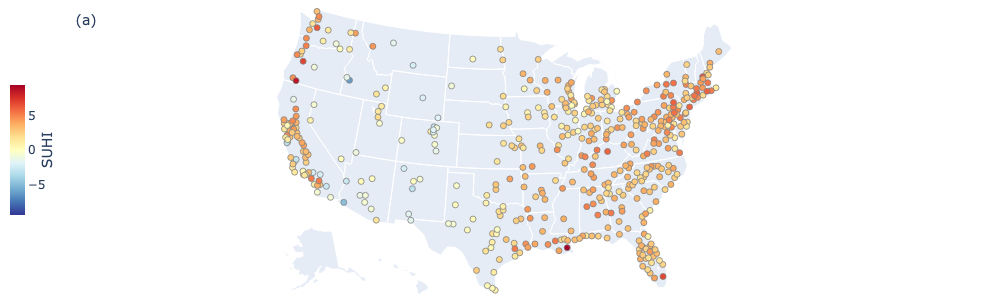

In [23]:
fig = go.Figure(go.Scattergeo(
            lon  = df['Lon'],
            lat  = df['Lat'],
            text = df['SUHI'].round(2).astype(str)+'<br>'+ df['Urban_name'],
            mode = 'markers',
            marker_color = df['SUHI'],
            marker=dict(
                            size=6,
                            opacity = 1, #0.8,
                            reversescale = True,
                            autocolorscale = False,
                            symbol = 'circle',
                            colorscale = 'RdYlBu',
                            cmin = df['SUHI'].min(),
                            color = df['SUHI'],
                            cmax = df['SUHI'].max(),
                            cmid=0,
                            cauto=True,
                            line = dict(
                                width = 0.8, #1,
                                color = 'gray' 
                            ),
                            colorbar=dict(
                                title=dict(
                                    text='SUHI', side='right'
                                ),
                                orientation='v', thickness=15,
                                x=0, y=150, 
                                len=0.5          
                            )
                         ),
            showlegend=False,
            name='SUHI'))

fig.update_layout(
        title={
        'text': '(a)',
        'x': 0.075,  # Position title at 5% from the left
        'y': 0.95,  # Position title at 95% from the bottom
        'xanchor': 'left', # Align left edge of title with x
        'yanchor': 'top', # Align top edge of title with y
        'font_size': 14
        },
        height=300, width=550, margin={'t':0,'l':0,'b':0,'r':0}, geo_scope='usa',
)
pio.write_image(fig, 'graphs/descriptive/map.jpg', scale=2)
pio.write_image(fig, 'graphs/descriptive/map.svg')
fig.show()